**CLAP-general variant (phase5j_artist_primary_cg).** Copy of `phase5j_artist_primary.ipynb` with the CLAP audio representation replaced by `laion/larger_clap_general` (`audio_features_clap_general.parquet`; the HF `larger_clap_music` conversion is defective, see Phase 2d and 5p). MuQ, MERT and SBERT results are unchanged by construction. Every output carries a `_cg` suffix; the original outputs are untouched.

# Phase 5j: Main results under the artist-filtered protocol (primary)

From the pre-submission review onward, the **primary evaluation protocol excludes every same-artist candidate** from
each query's ranking (and from the nDCG ideal ranking). Phase 5i showed that same-artist neighbours make up 7–8% of
MuQ top-10 lists (0.2% by chance), that 73.5% of same-artist pairs share a quadrant, and that they inflate audio more
than lyrics.

This notebook re-runs, under that protocol:
1. the Phase 5f main results: configuration selection on **filtered validation**, main table, paired tests, TOST,
   near-duplicate sensitivity, Figures 4 and 5 (P@K curves, per-quadrant P@10);
2. the Phase 5h relevance sensitivity (nDCG σ ∈ {0.05, 0.10, 0.20}, P@10(τ));
3. the Phase 4c coherence–retrieval analysis (Spearman, terciles, partial Spearman with confound controls) and
   Figure 8, on 70/15/15 test (as before) and additionally on 40/30/30 test.

The code is copied from 5f / 5h / 4c with only the exclusion added. Every output gets an `_artist` suffix; the
unfiltered files stay as they are.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, t as t_dist
from sklearn.preprocessing import StandardScaler

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')
ENC_DIR = os.path.join(OUT_DIR, 'encoders')
SIGMA, KMAX, N_BOOT, SEED = 0.10, 20, 10_000, 42
ALPHAS  = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
SCHEMES = {'tvt_70_15_15': '70/15/15', 'tvt_40_30_30': '40/30/30'}
QUADS   = ['Q1', 'Q2', 'Q3', 'Q4']
QLAB    = {'Q1': 'Happy', 'Q2': 'Angry', 'Q3': 'Sad', 'Q4': 'Calm'}
rng = np.random.default_rng(SEED)

lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))
cat_sids  = lyrics_df['song_id'].tolist()
cat_pos   = {s: i for i, s in enumerate(cat_sids)}
a_ids = pd.read_csv(os.path.join(ENC_DIR, 'audio_song_ids.csv'))['song_id'].tolist()
a_row = [{s: i for i, s in enumerate(a_ids)}[s] for s in cat_sids]
assert pd.read_csv(os.path.join(ENC_DIR, 'text_song_ids.csv'))['song_id'].tolist() == cat_sids

muq  = np.load(os.path.join(ENC_DIR, 'audio_muq.npy'),  mmap_mode='r')[a_row].astype(np.float64)
mert = np.load(os.path.join(ENC_DIR, 'audio_mert.npy'), mmap_mode='r')[a_row].astype(np.float64)
a_old = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet')).set_index('song_id').loc[cat_sids]
REPS = {'sbert': np.load(os.path.join(ENC_DIR, 'text_sbert_mpnet_trunc.npy')).astype(np.float64),
        'clap':  np.vstack(pd.read_parquet(os.path.join(OUT_DIR, 'audio_features_clap_general.parquet')).set_index('song_id').loc[cat_sids]['audio_clap_gen'].values).astype(np.float64)}
for L in range(13):
    REPS[f'muq_L{L}'] = muq[:, L]; REPS[f'mert_L{L}'] = mert[:, L]
del muq, mert
FAMILY = lambda r: r.split('_L')[0]

lab  = merged.set_index('song_id').loc[cat_sids]
quad = lab['quadrant'].values
Y    = lab[['arousal', 'valence']].values.astype(np.float64)
D_AV = np.linalg.norm(Y[:, None] - Y[None], axis=-1)

mm = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s for s, p in zip(mm['song_id'], mm['lyrics_path'])}
def read_split(modality, scheme, subset):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    ids = pd.read_csv(os.path.join(ROOT, folder, 'tvt_dataframes', scheme,
                                   f'{scheme}_{subset}_{modality}_balanced.csv'))['Song']
    return set(ids.map(lyr_stem_to_sid).dropna()) if modality == 'lyrics' else set(ids)
cat = set(cat_sids)
shared = {lbl: {sub: sorted(read_split('audio', sc, sub) & read_split('lyrics', sc, sub) & cat)
                for sub in ['train', 'validate', 'test']} for sc, lbl in SCHEMES.items()}
print({lbl: {k: len(v) for k, v in d.items()} for lbl, d in shared.items()})

{'70/15/15': {'train': 1187, 'validate': 305, 'test': 302}, '40/30/30': {'train': 475, 'validate': 616, 'test': 617}}


In [2]:
import re, unicodedata
def _norm_artist(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().lower().strip()
    return re.sub(r'[^a-z0-9]+', ' ', re.sub(r'^the\s+', '', s)).strip()
ART_ID = np.array([_norm_artist(a) for a in lab['artist'].values])
ART = ART_ID[:, None] == ART_ID[None]
np.fill_diagonal(ART, False)                          # the query itself is excluded separately
print(f'{len(set(ART_ID))} artist groups; mean same-artist candidates per track {ART.sum(1).mean():.2f}')

1086 artist groups; mean same-artist candidates per track 3.48


In [3]:
_unit = {}
def unit(rep, how):
    if (rep, how) not in _unit:
        X = REPS[rep]; X = StandardScaler().fit_transform(X) if how == 'z' else X
        _unit[(rep, how)] = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
    return _unit[(rep, how)]

def score_matrix(cfg, rows):
    # cfg: ('single', (rep, how)) | ('late', (repA, howA), (repT, howT), alpha) | ('early', (repA, howA), (repT, howT))
    if cfg[0] == 'single':
        X = unit(*cfg[1]); return X[rows] @ X.T
    A, T = unit(*cfg[1]), unit(*cfg[2])
    if cfg[0] == 'late':
        return cfg[3] * (A[rows] @ A.T) + (1 - cfg[3]) * (T[rows] @ T.T)
    E = np.hstack([A, T]) / np.sqrt(2)                                     # unit-norm concatenation
    return E[rows] @ E.T

DISC = 1 / np.log2(np.arange(2, KMAX + 2))
def topk(S, k):
    # same selection as Phase 5e (argpartition at exactly k, then sort): duplicate tracks in MERGE give exact score
    # ties, and partitioning at a different k can break them differently, so each k is partitioned on its own
    top = np.argpartition(-S, k, 1)[:, :k]
    return np.take_along_axis(top, np.take_along_axis(S, top, 1).argsort(1)[:, ::-1], 1)

def evaluate(cfg, qs, exclude=None):
    # exclude: optional boolean (N, N) mask of catalog pairs that may not be retrieved for each other
    rows = np.array([cat_pos[s] for s in qs])
    S = score_matrix(cfg, rows); S[np.arange(len(rows)), rows] = -np.inf
    if exclude is not None:
        S[exclude[rows]] = -np.inf
    PK = np.column_stack([(quad[topk(S, k)] == quad[rows][:, None]).mean(1) for k in range(1, KMAX + 1)])
    top = topk(S, 10)
    d = np.take_along_axis(D_AV[rows], top, 1)
    Dq = D_AV[rows].copy(); Dq[np.arange(len(rows)), rows] = np.inf
    if exclude is not None:
        Dq[exclude[rows]] = np.inf
    g = np.exp(-d**2 / (2 * SIGMA**2)); gi = np.exp(-np.sort(Dq, 1)[:, :10]**2 / (2 * SIGMA**2))
    return {'P@K': PK, 'nDCG@10': (g * DISC[:10]).sum(1) / (gi * DISC[:10]).sum(1),
            'AVdist@10': d.mean(1), 'quadrant': quad[rows], 'song_id': np.array(qs)}

def best_single(lbl, family):
    reps = [r for r in REPS if FAMILY(r) == family]
    cands = [(r, h) for r in reps for h in ['raw', 'z']]
    return max(cands, key=lambda c: evaluate(('single', c), shared[lbl]['validate'], exclude=ART)['P@K'][:, 9].mean())

def best_alpha(lbl, ca, ct):
    return max(ALPHAS, key=lambda al: evaluate(('late', ca, ct, al), shared[lbl]['validate'], exclude=ART)['P@K'][:, 9].mean())

CFG = {}
for lbl in SCHEMES.values():
    c = {f: best_single(lbl, f) for f in ['muq', 'mert', 'sbert', 'clap']}
    a_muq, a_clap = best_alpha(lbl, c['muq'], c['sbert']), best_alpha(lbl, c['clap'], c['sbert'])
    CFG[lbl] = {
        'audio-only (MuQ)':         ('single', c['muq']),
        'lyrics-only (SBERT)':      ('single', c['sbert']),
        f'late fusion (α={a_muq})': ('late', c['muq'], c['sbert'], a_muq),
        'early fusion (≡ α=0.5)':   ('early', c['muq'], c['sbert']),
        'audio-only (CLAP)':        ('single', c['clap']),
        f'late fusion CLAP+SBERT (α={a_clap})': ('late', c['clap'], c['sbert'], a_clap),
        'audio-only (MERT)':        ('single', c['mert']),
    }
    print(lbl, {k: v[1:] for k, v in CFG[lbl].items()})

# early fusion == late fusion at alpha = 0.5 (unit-norm concatenation)
q = shared['70/15/15']['test'][:50]; rows = np.array([cat_pos[s] for s in q])
c = CFG['70/15/15']
assert np.allclose(score_matrix(('early', c['audio-only (MuQ)'][1], c['lyrics-only (SBERT)'][1]), rows),
                   score_matrix(('late', c['audio-only (MuQ)'][1], c['lyrics-only (SBERT)'][1], 0.5), rows))
print('early fusion == late fusion at α = 0.5: verified')

70/15/15 {'audio-only (MuQ)': (('muq_L6', 'z'),), 'lyrics-only (SBERT)': (('sbert', 'z'),), 'late fusion (α=0.6)': (('muq_L6', 'z'), ('sbert', 'z'), 0.6), 'early fusion (≡ α=0.5)': (('muq_L6', 'z'), ('sbert', 'z')), 'audio-only (CLAP)': (('clap', 'z'),), 'late fusion CLAP+SBERT (α=0.4)': (('clap', 'z'), ('sbert', 'z'), 0.4), 'audio-only (MERT)': (('mert_L7', 'z'),)}


40/30/30 {'audio-only (MuQ)': (('muq_L6', 'z'),), 'lyrics-only (SBERT)': (('sbert', 'z'),), 'late fusion (α=0.6)': (('muq_L6', 'z'), ('sbert', 'z'), 0.6), 'early fusion (≡ α=0.5)': (('muq_L6', 'z'), ('sbert', 'z')), 'audio-only (CLAP)': (('clap', 'z'),), 'late fusion CLAP+SBERT (α=0.5)': (('clap', 'z'), ('sbert', 'z'), 0.5), 'audio-only (MERT)': (('mert_L6', 'z'),)}
early fusion == late fusion at α = 0.5: verified


In [4]:
RES = {lbl: {name: evaluate(cfg, shared[lbl]['test'], exclude=ART) for name, cfg in CFG[lbl].items()} for lbl in SCHEMES.values()}

def boot_ci(x, n=N_BOOT):
    idx = rng.integers(0, len(x), (n, len(x)))
    return np.percentile(x[idx].mean(1), [2.5, 97.5])

rows = []
for lbl, res in RES.items():
    for name, m in res.items():
        r = {'split': lbl, 'strategy': name, 'n': len(m['nDCG@10'])}
        for col, x in [('P@5', m['P@K'][:, 4]), ('P@10', m['P@K'][:, 9]), ('P@20', m['P@K'][:, 19]),
                       ('nDCG@10', m['nDCG@10']), ('AVdist@10', m['AVdist@10'])]:
            lo, hi = boot_ci(x); r.update({col: x.mean(), f'{col}_lo': lo, f'{col}_hi': hi})
        rows.append(r)
table = pd.DataFrame(rows)

ref = pd.read_csv(os.path.join(OUT_DIR, 'artist_filtered_main_table.csv'))
ref = ref[ref.condition == 'artist-filtered, re-selected']
for lbl in SCHEMES.values():
    for name in ['audio-only (MuQ)', 'lyrics-only (SBERT)', 'audio-only (MERT)', 'early fusion (≡ α=0.5)']:   # CLAP omitted: different checkpoint
        r5i = ref[(ref.split == lbl) & (ref.strategy == name)].iloc[0]
        r5j = table[(table.split == lbl) & (table.strategy == name)].iloc[0]
        assert abs(r5i['P@10'] - r5j['P@10']) < 1e-9 and abs(r5i['nDCG@10'] - r5j['nDCG@10']) < 1e-9, (lbl, name)
print('Matches Phase 5i (artist-filtered, re-selected on filtered validation).')

fmt = lambda r, c, d=3: f"{r[c]:.{d}f} [{r[c + '_lo']:.{d}f}, {r[c + '_hi']:.{d}f}]"
for lbl in SCHEMES.values():
    s = table[table.split == lbl]
    print(f'\n=== {lbl} shared test (n={s.n.iloc[0]}) ===')
    print(pd.DataFrame({c: s.apply(lambda r: fmt(r, c), axis=1).values for c in ['P@5', 'P@10', 'P@20', 'nDCG@10', 'AVdist@10']},
                       index=s.strategy.values).to_string())
table.to_csv(os.path.join(OUT_DIR, 'main_results_table_artist_cg.csv'), index=False)

Matches Phase 5i (artist-filtered, re-selected on filtered validation).

=== 70/15/15 shared test (n=302) ===
                                                 P@5                  P@10                  P@20               nDCG@10             AVdist@10
audio-only (MuQ)                0.637 [0.602, 0.673]  0.610 [0.579, 0.640]  0.588 [0.560, 0.617]  0.417 [0.389, 0.445]  0.214 [0.202, 0.226]
lyrics-only (SBERT)             0.620 [0.582, 0.658]  0.602 [0.567, 0.638]  0.595 [0.561, 0.629]  0.420 [0.392, 0.448]  0.204 [0.192, 0.216]
late fusion (α=0.6)             0.707 [0.672, 0.742]  0.690 [0.657, 0.722]  0.669 [0.640, 0.699]  0.471 [0.444, 0.499]  0.185 [0.173, 0.197]
early fusion (≡ α=0.5)          0.702 [0.667, 0.738]  0.694 [0.663, 0.725]  0.673 [0.643, 0.702]  0.473 [0.445, 0.501]  0.184 [0.172, 0.195]
audio-only (CLAP)               0.656 [0.621, 0.691]  0.644 [0.611, 0.676]  0.619 [0.587, 0.649]  0.440 [0.411, 0.469]  0.204 [0.191, 0.216]
late fusion CLAP+SBERT (α=0.4)  0.720 [0.684

In [5]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

trows = []
for lbl, res in RES.items():
    late = [k for k in res if k.startswith('late fusion (')][0]
    late_clap = [k for k in res if k.startswith('late fusion CLAP')][0]
    pairs = [(late, 'lyrics-only (SBERT)'), (late, 'audio-only (MuQ)'), ('early fusion (≡ α=0.5)', 'lyrics-only (SBERT)'),
             ('audio-only (MuQ)', 'lyrics-only (SBERT)'), ('audio-only (MuQ)', 'audio-only (CLAP)'), (late, late_clap)]
    for metric, get in [('P@10', lambda m: m['P@K'][:, 9]), ('nDCG@10', lambda m: m['nDCG@10'])]:
        block = []
        for a, b in pairs:
            d = get(res[a]) - get(res[b]); lo, hi = boot_ci(d)
            p = wilcoxon(get(res[a]), get(res[b]), zero_method='pratt').pvalue if (d != 0).any() else 1.0
            block.append({'split': lbl, 'metric': metric, 'comparison': f'{a} − {b}', 'diff': d.mean(), 'lo': lo, 'hi': hi, 'p': p})
        for r, ph in zip(block, holm([r['p'] for r in block])):
            r['p_holm'] = ph
        trows += block
tests = pd.DataFrame(trows)
print(tests.to_string(index=False, float_format=lambda x: f'{x:.3g}'))
tests.to_csv(os.path.join(OUT_DIR, 'main_results_tests_artist_cg.csv'), index=False)

   split  metric                                           comparison     diff      lo       hi        p   p_holm
70/15/15    P@10            late fusion (α=0.6) − lyrics-only (SBERT)   0.0877  0.0593    0.118 7.88e-08 3.15e-07
70/15/15    P@10               late fusion (α=0.6) − audio-only (MuQ)   0.0798  0.0573    0.103 2.28e-11 1.37e-10
70/15/15    P@10         early fusion (≡ α=0.5) − lyrics-only (SBERT)   0.0921  0.0659    0.119 1.54e-10  7.7e-10
70/15/15    P@10               audio-only (MuQ) − lyrics-only (SBERT)  0.00795 -0.0295   0.0454    0.916    0.916
70/15/15    P@10                 audio-only (MuQ) − audio-only (CLAP)  -0.0338 -0.0573  -0.0103  0.00103  0.00308
70/15/15    P@10 late fusion (α=0.6) − late fusion CLAP+SBERT (α=0.4)  -0.0152 -0.0354  0.00464    0.172    0.344
70/15/15 nDCG@10            late fusion (α=0.6) − lyrics-only (SBERT)   0.0514  0.0319   0.0711 3.56e-06 1.42e-05
70/15/15 nDCG@10               late fusion (α=0.6) − audio-only (MuQ)   0.0543  0.0394  

In [6]:
def near_dup(X):
    X = X / np.linalg.norm(X, axis=1, keepdims=True); S = X @ X.T; np.fill_diagonal(S, -1)
    return S > 0.9999
DUP = near_dup(unit('muq_L6', 'z')) | near_dup(unit('mert_L7', 'z')) | near_dup(REPS['sbert'])
i, j = np.where(np.triu(DUP))
dups = pd.DataFrame({'song_id_a': np.array(cat_sids)[i], 'song_id_b': np.array(cat_sids)[j]})
dups = dups.join(lab[['artist', 'title', 'quadrant']].reset_index(drop=True).iloc[i].reset_index(drop=True).add_suffix('_a'))
dups = dups.join(lab[['artist', 'title', 'quadrant']].reset_index(drop=True).iloc[j].reset_index(drop=True).add_suffix('_b'))
dups['same_quadrant'] = dups.quadrant_a == dups.quadrant_b
print(f'{len(dups)} near-duplicate pairs ({DUP.any(1).sum()} tracks); same quadrant: {dups.same_quadrant.sum()}')
print(dups[['artist_a', 'title_a', 'artist_b', 'title_b', 'quadrant_a', 'quadrant_b']].to_string(index=False))
# merge_near_duplicates.csv is written by Phase 5f (identical content); not rewritten here

srows = []
for lbl in SCHEMES.values():
    for name, cfg in CFG[lbl].items():
        a, b = RES[lbl][name], evaluate(cfg, shared[lbl]['test'], exclude=DUP | ART)
        srows.append({'split': lbl, 'strategy': name, 'P@10': a['P@K'][:, 9].mean(), 'P@10_dedup': b['P@K'][:, 9].mean(),
                      'nDCG@10': a['nDCG@10'].mean(), 'nDCG@10_dedup': b['nDCG@10'].mean()})
sens = pd.DataFrame(srows)
sens['ΔP@10'] = sens['P@10_dedup'] - sens['P@10']; sens['ΔnDCG@10'] = sens['nDCG@10_dedup'] - sens['nDCG@10']
print(sens.round(4).to_string(index=False))
sens.to_csv(os.path.join(OUT_DIR, 'main_results_dedup_sensitivity_artist_cg.csv'), index=False)

14 near-duplicate pairs (28 tracks); same quadrant: 13
                      artist_a                      title_a           artist_b                           title_b quadrant_a quadrant_b
                          Enya        Journey of the Angels               Enya             Journey of the Angels         Q4         Q4
                        Prince                         Kiss             Prince                              Kiss         Q1         Q1
               Luther Vandross               Never Too Much    Luther Vandross                    Never Too Much         Q1         Q1
                   The Beatles              Twist and Shout The Isley Brothers                   Twist and Shout         Q1         Q1
                   Patsy Cline Just a Closer Walk With Thee      Willie Nelson      Just a Closer Walk With Thee         Q4         Q4
                 Hank Williams              I'm So Lonesome      Hank Williams      I'm So Lonesome, I Could Cry         Q3         Q3


   split                       strategy   P@10  P@10_dedup  nDCG@10  nDCG@10_dedup   ΔP@10  ΔnDCG@10
70/15/15               audio-only (MuQ) 0.6099      0.6099   0.4171         0.4168  0.0000   -0.0003
70/15/15            lyrics-only (SBERT) 0.6020      0.6020   0.4201         0.4198  0.0000   -0.0002
70/15/15            late fusion (α=0.6) 0.6897      0.6891   0.4714         0.4711 -0.0007   -0.0004
70/15/15         early fusion (≡ α=0.5) 0.6940      0.6934   0.4727         0.4725 -0.0007   -0.0002
70/15/15              audio-only (CLAP) 0.6437      0.6437   0.4398         0.4398  0.0000    0.0000
70/15/15 late fusion CLAP+SBERT (α=0.4) 0.7050      0.7040   0.4792         0.4784 -0.0010   -0.0008
70/15/15              audio-only (MERT) 0.6017      0.6013   0.4117         0.4115 -0.0003   -0.0002
40/30/30               audio-only (MuQ) 0.6185      0.6185   0.4280         0.4278  0.0000   -0.0002
40/30/30            lyrics-only (SBERT) 0.6120      0.6120   0.4279         0.4276  0.0000 

In [7]:
MARGIN = {'P@10': 0.05, 'nDCG@10': 0.03}
erows = []
for lbl, res in RES.items():
    for audio in ['audio-only (MuQ)', 'audio-only (MERT)']:
        for metric, get in [('P@10', lambda m: m['P@K'][:, 9]), ('nDCG@10', lambda m: m['nDCG@10'])]:
            d = get(res[audio]) - get(res['lyrics-only (SBERT)']); n = len(d)
            idx = rng.integers(0, n, (N_BOOT, n)); bs = d[idx].mean(1)
            lo90, hi90 = np.percentile(bs, [5, 95])
            se = d.std(ddof=1) / np.sqrt(n); m = MARGIN[metric]
            p_tost = max(t_dist.sf((d.mean() + m) / se, n - 1), t_dist.cdf((d.mean() - m) / se, n - 1))
            erows.append({'split': lbl, 'audio': audio, 'metric': metric, 'mean_diff (audio − lyrics)': d.mean(),
                          'ci90_lo': lo90, 'ci90_hi': hi90, 'margin': m, 'equivalent (bootstrap)': (lo90 > -m) and (hi90 < m),
                          'p_TOST (paired t)': p_tost, 'smallest_equiv_margin': max(abs(lo90), abs(hi90))})
equiv = pd.DataFrame(erows)
print(equiv.to_string(index=False, float_format=lambda x: f'{x:.4g}'))
equiv.to_csv(os.path.join(OUT_DIR, 'equivalence_audio_vs_lyrics_artist_cg.csv'), index=False)

   split             audio  metric  mean_diff (audio − lyrics)  ci90_lo  ci90_hi  margin  equivalent (bootstrap)  p_TOST (paired t)  smallest_equiv_margin
70/15/15  audio-only (MuQ)    P@10                    0.007947  -0.0232  0.03907    0.05                    True            0.01401                0.03907
70/15/15  audio-only (MuQ) nDCG@10                   -0.002918 -0.02408  0.01823    0.03                    True            0.01851                0.02408
70/15/15 audio-only (MERT)    P@10                  -0.0003311 -0.03247  0.03245    0.05                    True           0.006544                0.03247
70/15/15 audio-only (MERT) nDCG@10                   -0.008385 -0.03078  0.01378    0.03                   False            0.05604                0.03078
40/30/30  audio-only (MuQ)    P@10                    0.006483 -0.01507  0.02755    0.05                    True          0.0004538                0.02755
40/30/30  audio-only (MuQ) nDCG@10                   0.0001214 -0.0154

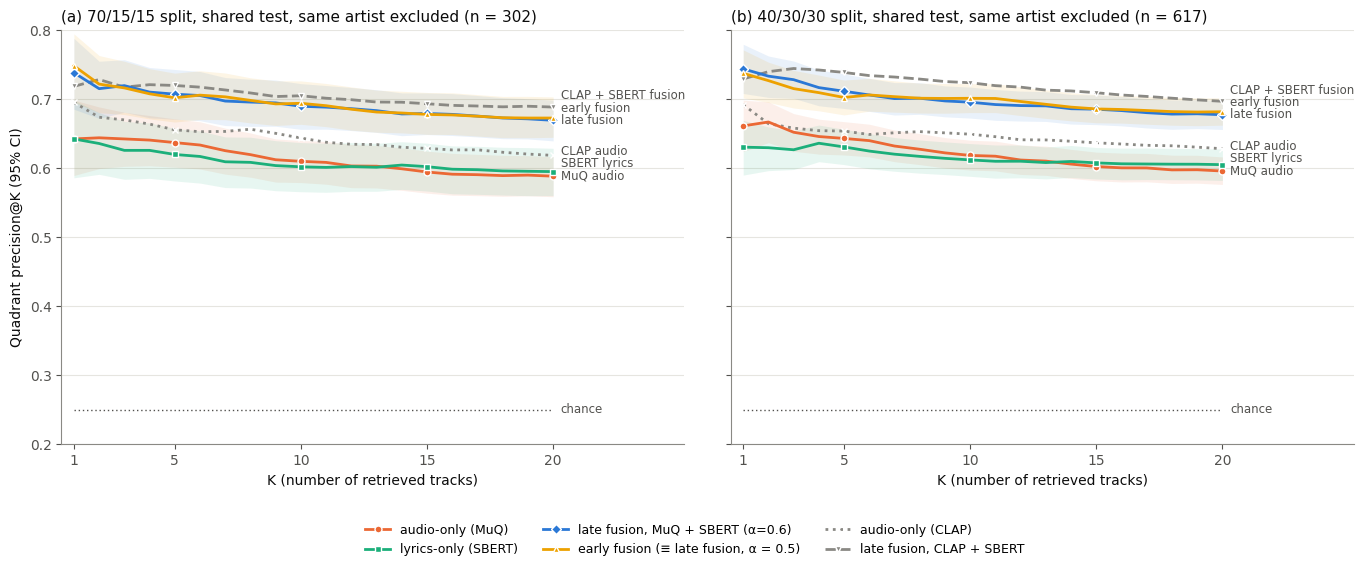

In [8]:
INK, INK2, MUTED, GRID = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e0'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': MUTED,
                     'xtick.color': INK2, 'ytick.color': INK2, 'axes.labelcolor': INK, 'font.size': 10,
                     'axes.titlesize': 11, 'axes.titlecolor': INK, 'legend.frameon': False})
def style(name):
    if name.startswith('late fusion CLAP'): return dict(color=MUTED, ls='--', marker='v', label='late fusion, CLAP + SBERT')
    if name.startswith('late fusion'):      return dict(color='#2a78d6', ls='-', marker='D', label=f'late fusion, MuQ + SBERT ({name.split("(")[1][:-1]})')
    return {'audio-only (MuQ)':       dict(color='#eb6834', ls='-', marker='o', label='audio-only (MuQ)'),
            'lyrics-only (SBERT)':    dict(color='#1baf7a', ls='-', marker='s', label='lyrics-only (SBERT)'),
            'early fusion (≡ α=0.5)': dict(color='#eda100', ls='-', marker='^', label='early fusion (≡ late fusion, α = 0.5)'),
            'audio-only (CLAP)':      dict(color=MUTED, ls=':', marker='x', label='audio-only (CLAP)'),
            'audio-only (MERT)':      None}[name]

# ── Figure: Precision@K curves, both splits (replaces Figure 4) ──────────────────────────────────────────────
K = np.arange(1, KMAX + 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), sharey=True)
for ax, lbl in zip(axes, SCHEMES.values()):
    res = RES[lbl]; ends = []
    for name, m in res.items():
        st = style(name)
        if st is None: continue
        P = m['P@K']; mean = P.mean(0)
        idx = rng.integers(0, len(P), (2000, len(P))); bs = P[idx].mean(1)
        lo, hi = np.percentile(bs, [2.5, 97.5], axis=0)
        main = st['color'] != MUTED
        if main:
            ax.fill_between(K, lo, hi, color=st['color'], alpha=0.10, lw=0)
        ax.plot(K, mean, color=st['color'], ls=st['ls'], lw=2, marker=st['marker'], ms=5 if main else 4,
                markevery=[0, 4, 9, 14, 19], mec='white', mew=1, label=st['label'], zorder=3 if main else 2)
        END = {'audio-only (MuQ)': 'MuQ audio', 'lyrics-only (SBERT)': 'SBERT lyrics', 'early fusion (≡ α=0.5)': 'early fusion',
               'audio-only (CLAP)': 'CLAP audio'}
        ends.append((mean[-1], END.get(name, 'CLAP + SBERT fusion' if 'CLAP' in name else 'late fusion'), st['color']))
    ax.plot([1, KMAX], [0.25, 0.25], color=INK2, lw=1, ls=(0, (1, 2)))
    ax.text(KMAX + 0.3, 0.25, 'chance', va='center', fontsize=8.5, color=INK2)
    # direct end labels, nudged apart so they never overlap
    ends.sort(); ys = []
    for y, _, _ in ends:
        ys.append(max(y, ys[-1] + 0.018) if ys else y)
    for (y, txt, c), yl in zip(ends, ys):
        ax.text(KMAX + 0.3, yl, txt, va='center', fontsize=8.5, color=INK2)
    ax.set_xlim(0.5, KMAX + 5.2); ax.set_xticks([1, 5, 10, 15, 20]); ax.set_ylim(0.2, 0.8)
    ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
    ax.set_xlabel('K (number of retrieved tracks)')
    ax.set_title(f'({"ab"[list(SCHEMES.values()).index(lbl)]}) {lbl} split, shared test, same artist excluded (n = {len(res["audio-only (MuQ)"]["P@K"])})', loc='left')
axes[0].set_ylabel('Quadrant precision@K (95% CI)')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=3, fontsize=9, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(os.path.join(OUT_DIR, 'main_precision_at_k_artist_cg.png'), dpi=200, bbox_inches='tight'); plt.show()

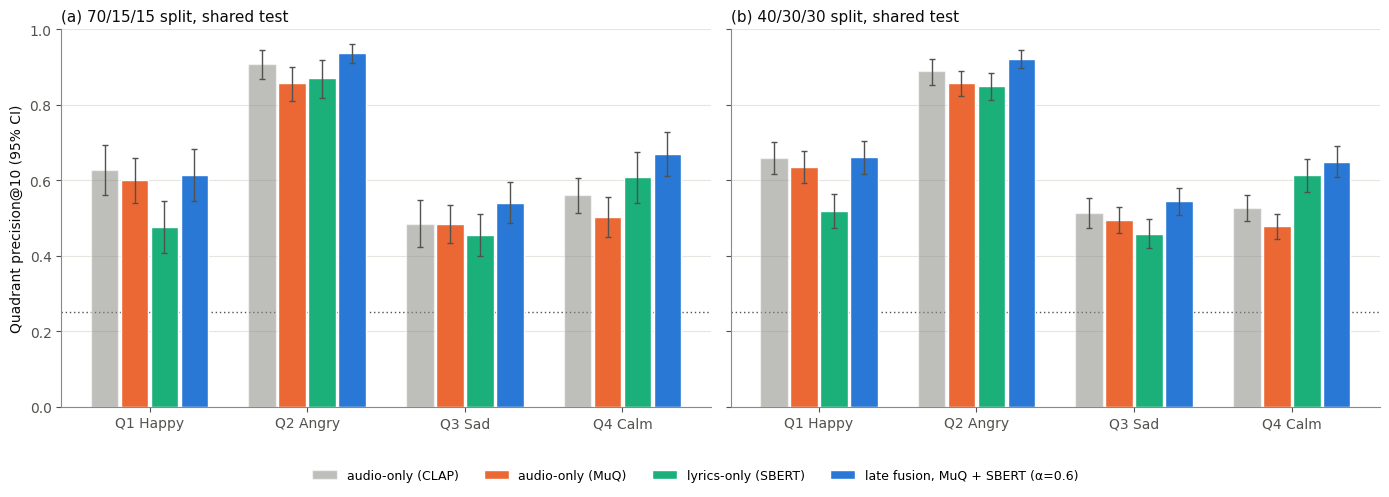

quadrant                         Q1     Q2     Q3     Q4
split    strategy                                       
40/30/30 audio-only (CLAP)    0.659  0.889  0.514  0.527
         audio-only (MuQ)     0.635  0.858  0.495  0.478
         late fusion (α=0.6)  0.661  0.922  0.544  0.648
         lyrics-only (SBERT)  0.520  0.849  0.458  0.613
70/15/15 audio-only (CLAP)    0.627  0.909  0.483  0.560
         audio-only (MuQ)     0.600  0.857  0.483  0.503
         late fusion (α=0.6)  0.613  0.939  0.540  0.671
         lyrics-only (SBERT)  0.476  0.872  0.455  0.609


In [9]:
# ── Figure: per-quadrant P@10 (replaces Figure 6) ────────────────────────────────────────────────────────────
SHOW = ['audio-only (MuQ)', 'lyrics-only (SBERT)', None, 'audio-only (CLAP)']       # None = late fusion (name varies)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
qrows = []
for ax, lbl in zip(axes, SCHEMES.values()):
    res = RES[lbl]
    names = [n if n else [k for k in res if k.startswith('late fusion (')][0] for n in SHOW]
    order = [names[3], names[0], names[1], names[2]]                                # CLAP, MuQ, SBERT, fusion
    w = 0.19; x = np.arange(4)
    for k, name in enumerate(order):
        st = style(name); m = res[name]; vals, err = [], [[], []]
        for q in QUADS:
            v = m['P@K'][m['quadrant'] == q, 9]; lo, hi = boot_ci(v, 2000)
            vals.append(v.mean()); err[0].append(v.mean() - lo); err[1].append(hi - v.mean())
            qrows.append({'split': lbl, 'strategy': name, 'quadrant': q, 'n': len(v), 'P@10': v.mean(), 'lo': lo, 'hi': hi})
        ax.bar(x + (k - 1.5) * w, vals, w * 0.92, color=st['color'], alpha=0.55 if st['color'] == MUTED else 1,
               edgecolor='white', lw=1, label=st['label'], zorder=2)
        ax.errorbar(x + (k - 1.5) * w, vals, yerr=err, fmt='none', ecolor=INK2, elinewidth=1, capsize=2, zorder=3)
    ax.axhline(0.25, color=INK2, lw=1, ls=(0, (1, 2)), zorder=1)
    ax.set_xticks(x); ax.set_xticklabels([f'{q} {QLAB[q]}' for q in QUADS])
    ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True); ax.set_ylim(0, 1)
    ax.set_title(f'({"ab"[list(SCHEMES.values()).index(lbl)]}) {lbl} split, shared test', loc='left')
axes[0].set_ylabel('Quadrant precision@10 (95% CI)')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='lower center', ncol=4, fontsize=9, bbox_to_anchor=(0.5, -0.04))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.savefig(os.path.join(OUT_DIR, 'main_per_quadrant_p10_artist_cg.png'), dpi=200, bbox_inches='tight'); plt.show()
pd.DataFrame(qrows).to_csv(os.path.join(OUT_DIR, 'main_per_quadrant_p10_artist_cg.csv'), index=False)
print(pd.DataFrame(qrows).pivot_table(index=['split', 'strategy'], columns='quadrant', values='P@10').round(3).to_string())

## Relevance sensitivity (Phase 5h) under the artist filter
Same metrics as 5h. The per-query chance of P@10(τ) is computed over the candidates that remain after the filter.

In [10]:
SIGMAS = [0.05, 0.10, 0.20]
TAUS   = [0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.30]
K = 10
PER = {}
for lbl in SCHEMES.values():
    qs = shared[lbl]['test']; rows = np.array([cat_pos[s] for s in qs])
    Dq = D_AV[rows].copy(); Dq[np.arange(len(rows)), rows] = np.inf; Dq[ART[rows]] = np.inf
    d_ideal = np.sort(Dq, 1)[:, :K]; others = np.isfinite(Dq)
    chance = {t: ((Dq <= t) & others).sum(1) / others.sum(1) for t in TAUS}
    late = [k for k in CFG[lbl] if k.startswith('late fusion (')][0]
    for name in ['audio-only (MuQ)', 'lyrics-only (SBERT)', late, 'early fusion (≡ α=0.5)']:
        S = score_matrix(CFG[lbl][name], rows); S[np.arange(len(rows)), rows] = -np.inf; S[ART[rows]] = -np.inf
        top = topk(S, K); d = np.take_along_axis(D_AV[rows], top, 1)
        m = {'P@10 (quadrant)': (quad[top] == quad[rows][:, None]).mean(1)}
        for s in SIGMAS:
            g, gi = np.exp(-d**2 / (2 * s**2)), np.exp(-d_ideal**2 / (2 * s**2))
            m[f'nDCG@10 σ={s}'] = (g * DISC[:K]).sum(1) / (gi * DISC[:K]).sum(1)
        for t in TAUS:
            m[f'P@10(τ={t})'] = (d <= t).mean(1)
        PER[(lbl, name)] = m
        assert abs(m['P@10 (quadrant)'].mean() - RES[lbl][name]['P@K'][:, 9].mean()) < 1e-9
        assert abs(m['nDCG@10 σ=0.1'].mean() - RES[lbl][name]['nDCG@10'].mean()) < 1e-9
    PER[(lbl, 'chance')] = {f'P@10(τ={t})': chance[t] for t in TAUS} | {'P@10 (quadrant)': np.full(len(rows), np.nan)}
print('Quadrant P@10 and nDCG@10 (σ = 0.10) match the artist-filtered main table.')

srows = []
for (lbl, name), m in PER.items():
    for metric, x in m.items():
        if np.isnan(x).all(): continue
        lo, hi = boot_ci(x) if name != 'chance' else (np.nan, np.nan)
        srows.append({'split': lbl, 'strategy': name, 'metric': metric, 'mean': x.mean(), 'lo': lo, 'hi': hi})
rsumm = pd.DataFrame(srows)
rsumm.to_csv(os.path.join(OUT_DIR, 'relevance_sensitivity_main_artist_cg.csv'), index=False)
for lbl in SCHEMES.values():
    print(f'\n=== {lbl} test, same artist excluded ===')
    print(rsumm[rsumm.split == lbl].pivot(index='metric', columns='strategy', values='mean').round(3).to_string())

trows = []
metrics = [f'nDCG@10 σ={s}' for s in SIGMAS] + [f'P@10(τ={t})' for t in TAUS]
for lbl in SCHEMES.values():
    late = [k for k in CFG[lbl] if k.startswith('late fusion (')][0]
    pairs = [(late, 'lyrics-only (SBERT)'), (late, 'audio-only (MuQ)'), ('audio-only (MuQ)', 'lyrics-only (SBERT)')]
    for metric in metrics:
        block = []
        for a, b in pairs:
            xa, xb = PER[(lbl, a)][metric], PER[(lbl, b)][metric]; d = xa - xb; lo, hi = boot_ci(d)
            p = wilcoxon(xa, xb, zero_method='pratt').pvalue if (d != 0).any() else 1.0
            block.append({'split': lbl, 'metric': metric, 'comparison': f'{a} − {b}', 'diff': d.mean(), 'lo': lo, 'hi': hi, 'p': p})
        for r, ph in zip(block, holm([r['p'] for r in block])):
            r['p_holm'] = ph
        trows += block
rtests = pd.DataFrame(trows)
rtests.to_csv(os.path.join(OUT_DIR, 'relevance_sensitivity_main_tests_artist_cg.csv'), index=False)
print('\nMuQ − SBERT under each relevance definition (unfiltered 5h value for comparison):')
old = pd.read_csv(os.path.join(OUT_DIR, 'relevance_sensitivity_main_tests.csv'))
mm_ = rtests[rtests.comparison == 'audio-only (MuQ) − lyrics-only (SBERT)'].merge(
    old[old.comparison == 'audio-only (MuQ) − lyrics-only (SBERT)'][['split', 'metric', 'diff', 'p_holm']],
    on=['split', 'metric'], suffixes=('', '_unfiltered'))
print(mm_[['split', 'metric', 'diff', 'lo', 'hi', 'p_holm', 'diff_unfiltered', 'p_holm_unfiltered']].to_string(
    index=False, float_format=lambda x: f'{x:.3g}'))
print('\nFusion − lyrics, minimum over all σ/τ definitions:')
fl = rtests[rtests.comparison.str.endswith('− lyrics-only (SBERT)') & rtests.comparison.str.startswith('late')]
print(fl.groupby('split').agg(min_diff=('diff', 'min'), max_p_holm=('p_holm', 'max')).to_string())

Quadrant P@10 and nDCG@10 (σ = 0.10) match the artist-filtered main table.



=== 70/15/15 test, same artist excluded ===
strategy         audio-only (MuQ)  chance  early fusion (≡ α=0.5)  late fusion (α=0.6)  lyrics-only (SBERT)
metric                                                                                                     
P@10 (quadrant)             0.610     NaN                   0.694                0.690                0.602
P@10(τ=0.05)                0.177   0.057                   0.207                0.210                0.168
P@10(τ=0.075)               0.292   0.101                   0.322                0.327                0.272
P@10(τ=0.1)                 0.384   0.145                   0.433                0.436                0.375
P@10(τ=0.15)                0.514   0.225                   0.590                0.584                0.517
P@10(τ=0.2)                 0.584   0.305                   0.672                0.667                0.612
P@10(τ=0.25)                0.634   0.395                   0.724                0.719     


MuQ − SBERT under each relevance definition (unfiltered 5h value for comparison):
   split         metric     diff       lo       hi   p_holm  diff_unfiltered  p_holm_unfiltered
70/15/15 nDCG@10 σ=0.05  0.00835  -0.0106   0.0273    0.744           0.0291              0.011
70/15/15  nDCG@10 σ=0.1 -0.00292   -0.028   0.0227      0.6           0.0136              0.463
70/15/15  nDCG@10 σ=0.2  -0.0217  -0.0476  0.00422   0.0643         -0.00983              0.334
70/15/15   P@10(τ=0.05)  0.00894  -0.0116   0.0298    0.548           0.0291             0.0121
70/15/15  P@10(τ=0.075)   0.0199 -0.00364   0.0444    0.202           0.0374            0.00783
70/15/15    P@10(τ=0.1)  0.00993  -0.0175   0.0368    0.554           0.0278             0.0918
70/15/15   P@10(τ=0.15) -0.00331  -0.0361   0.0295    0.594           0.0119              0.815
70/15/15    P@10(τ=0.2)  -0.0275  -0.0613  0.00695   0.0627          -0.0139              0.264
70/15/15   P@10(τ=0.25)  -0.0417  -0.0752 -0.00861   

## Coherence and retrieval quality (Phase 4c sections 5 and 10) under the artist filter
Coherence scores (cross-fitted MuQ L7 / SBERT probes) do not involve retrieval and are unchanged; only the per-query
outcomes are recomputed with same-artist candidates excluded. 70/15/15 test is the reported analysis (as before);
40/30/30 test (n = 617, different queries, same coherence scores) is added for power. The unfiltered 70/15/15
correlations are recomputed and checked against `coherence_confound_check_muq.csv`.

In [11]:
from scipy.stats import spearmanr, rankdata
CENTER = np.array([0.5, 0.5])
coh = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq.parquet')).set_index('song_id')

def partial_spearman(x, y, Z):
    rx, ry = rankdata(x), rankdata(y)
    if Z.shape[1]:
        Zr = np.column_stack([np.ones(len(x))] + [rankdata(z) for z in Z.T])
        rx = rx - Zr @ np.linalg.lstsq(Zr, rx, rcond=None)[0]
        ry = ry - Zr @ np.linalg.lstsq(Zr, ry, rcond=None)[0]
    r = np.corrcoef(rx, ry)[0, 1]; df = len(x) - 2 - Z.shape[1]
    return r, 2 * t_dist.sf(abs(r) * np.sqrt(df / (1 - r**2)), df)

SETS = {'none': [], 'label intensity': ['label_dist_center'], 'boundary distance': ['label_dist_boundary'],
        'predicted intensity': ['pred_dist_center'], 'all three': ['label_dist_center', 'label_dist_boundary', 'pred_dist_center']}

def coherence_outcomes(lbl, exclude):
    late = [k for k in CFG[lbl] if k.startswith('late fusion (')][0]
    R = {n: evaluate(CFG[lbl][n], shared[lbl]['test'], exclude=exclude) for n in ['audio-only (MuQ)', 'lyrics-only (SBERT)', late]}
    ids = R['audio-only (MuQ)']['song_id']
    out = pd.DataFrame({'P10_audio_only': R['audio-only (MuQ)']['P@K'][:, 9], 'P10_lyrics_only': R['lyrics-only (SBERT)']['P@K'][:, 9],
                        'P10_late_0.6': R[late]['P@K'][:, 9], 'nDCG10_audio_only': R['audio-only (MuQ)']['nDCG@10'],
                        'nDCG10_lyrics_only': R['lyrics-only (SBERT)']['nDCG@10'], 'nDCG10_late_0.6': R[late]['nDCG@10']}, index=ids)
    assert late == 'late fusion (α=0.6)'
    return out

def coherence_tables(lbl, out):
    ct = coh.loc[out.index]
    cov = pd.DataFrame({'label_dist_center': np.linalg.norm(ct[['arousal', 'valence']].values - CENTER, axis=1),
                        'label_dist_boundary': np.minimum(np.abs(ct.arousal - 0.5), np.abs(ct.valence - 0.5)).values,
                        'pred_dist_center': 0.5 * (np.linalg.norm(ct[['pred_audio_arousal', 'pred_audio_valence']].values - CENTER, axis=1)
                                                   + np.linalg.norm(ct[['pred_lyrics_arousal', 'pred_lyrics_valence']].values - CENTER, axis=1))},
                       index=out.index)
    rows = []
    for outcome in out.columns:
        for sname, cols in SETS.items():
            r, pv = partial_spearman(ct.coh_cos.values, out[outcome].values, cov[cols].values)
            rows.append({'split': lbl, 'outcome': outcome, 'controls': sname, 'partial_spearman': r, 'p': pv})
    pc = pd.DataFrame(rows); pc['p_holm'] = np.nan
    for sname in SETS:
        i = pc.controls == sname; pc.loc[i, 'p_holm'] = holm(pc.loc[i, 'p'].values)
    info = []
    for score in ['coh_cos', 'coh_euc']:
        for o in out.columns:
            r, p = spearmanr(ct[score], out[o]); info.append({'split': lbl, 'coherence': score, 'outcome': o, 'spearman': r, 'p': p})
        r, p = spearmanr(ct[score], out['P10_late_0.6'] - out['P10_lyrics_only'])
        info.append({'split': lbl, 'coherence': score, 'outcome': 'fusion gain P@10 (late − lyrics)', 'spearman': r, 'p': p})
    terc = pd.qcut(ct.coh_cos, 3, labels=['low', 'mid', 'high'])
    tt = out.groupby(terc.values, observed=True).mean(); tt.insert(0, 'n', out.groupby(terc.values, observed=True).size())
    tt.insert(0, 'split', lbl)
    st = out.groupby(ct.status_cos.values).mean(); st.insert(0, 'n', out.groupby(ct.status_cos.values).size()); st.insert(0, 'split', lbl)
    return pc, pd.DataFrame(info), tt, st

# sanity: unfiltered 70/15/15 reproduces Phase 4c
pc0, *_ = coherence_tables('70/15/15', coherence_outcomes('70/15/15', None))
ref = pd.read_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq.csv'))
chk = pc0.merge(ref, on=['outcome', 'controls'], suffixes=('', '_4c'))
print('max |Δ partial Spearman| vs Phase 4c (unfiltered):', float((chk.partial_spearman - chk.partial_spearman_4c).abs().max()))

PC, INFO, TERC, STAT = [], [], [], []
OUTS = {}
for lbl in SCHEMES.values():
    OUTS[lbl] = coherence_outcomes(lbl, ART)
    a, b, c, d = coherence_tables(lbl, OUTS[lbl]); PC.append(a); INFO.append(b); TERC.append(c); STAT.append(d)
pc_all, info_all = pd.concat(PC), pd.concat(INFO)
terc_all = pd.concat(TERC).rename_axis('tercile').reset_index()
stat_all = pd.concat(STAT).rename_axis('status_cos').reset_index()
pc_all[pc_all.split == '70/15/15'].drop(columns='split').to_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq_artist_cg.csv'), index=False)
pc_all.to_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq_artist_both_splits_cg.csv'), index=False)
info_all.to_csv(os.path.join(OUT_DIR, 'coherence_vs_retrieval_artist_cg.csv'), index=False)
terc_all.to_csv(os.path.join(OUT_DIR, 'coherence_terciles_artist_cg.csv'), index=False)
stat_all.to_csv(os.path.join(OUT_DIR, 'coherence_status_retrieval_artist_cg.csv'), index=False)

for lbl in SCHEMES.values():
    print(f'\n=== {lbl} test, same artist excluded (n = {len(OUTS[lbl])}) ===')
    i = info_all[info_all.split == lbl]
    print(i.drop(columns='split').to_string(index=False, float_format=lambda x: f'{x:.3g}'))
    p = pc_all[pc_all.split == lbl]
    tab = p.pivot(index='outcome', columns='controls', values='partial_spearman')[list(SETS)]
    star = p.pivot(index='outcome', columns='controls', values='p_holm')[list(SETS)] < 0.05
    print('Partial Spearman (* = Holm p < 0.05 within control set):')
    print(tab.round(3).astype(str).where(~star, tab.round(3).astype(str) + '*').to_string())
    print('By coherence tercile:'); print(terc_all[terc_all.split == lbl].round(3).to_string(index=False))
    print('By coherence status:'); print(stat_all[stat_all.split == lbl].round(3).to_string(index=False))
print('\nmax Holm p (70/15/15, P@10 outcomes):', pc_all[(pc_all.split == '70/15/15') & pc_all.outcome.str.startswith('P10')].p_holm.max())

max |Δ partial Spearman| vs Phase 4c (unfiltered): 5.551115123125783e-17



=== 70/15/15 test, same artist excluded (n = 302) ===
coherence                          outcome  spearman        p
  coh_cos                   P10_audio_only     0.342 1.08e-09
  coh_cos                  P10_lyrics_only     0.385  4.3e-12
  coh_cos                     P10_late_0.6     0.314  2.5e-08
  coh_cos                nDCG10_audio_only     0.335 2.38e-09
  coh_cos               nDCG10_lyrics_only     0.335 2.47e-09
  coh_cos                  nDCG10_late_0.6     0.321 1.13e-08
  coh_cos fusion gain P@10 (late − lyrics)   -0.0965   0.0943
  coh_euc                   P10_audio_only     0.119   0.0387
  coh_euc                  P10_lyrics_only     0.294 2.03e-07
  coh_euc                     P10_late_0.6     0.148  0.00983
  coh_euc                nDCG10_audio_only     0.145   0.0116
  coh_euc               nDCG10_lyrics_only     0.256 6.42e-06
  coh_euc                  nDCG10_late_0.6     0.172  0.00275
  coh_euc fusion gain P@10 (late − lyrics)    -0.179  0.00177
Partial Spearma

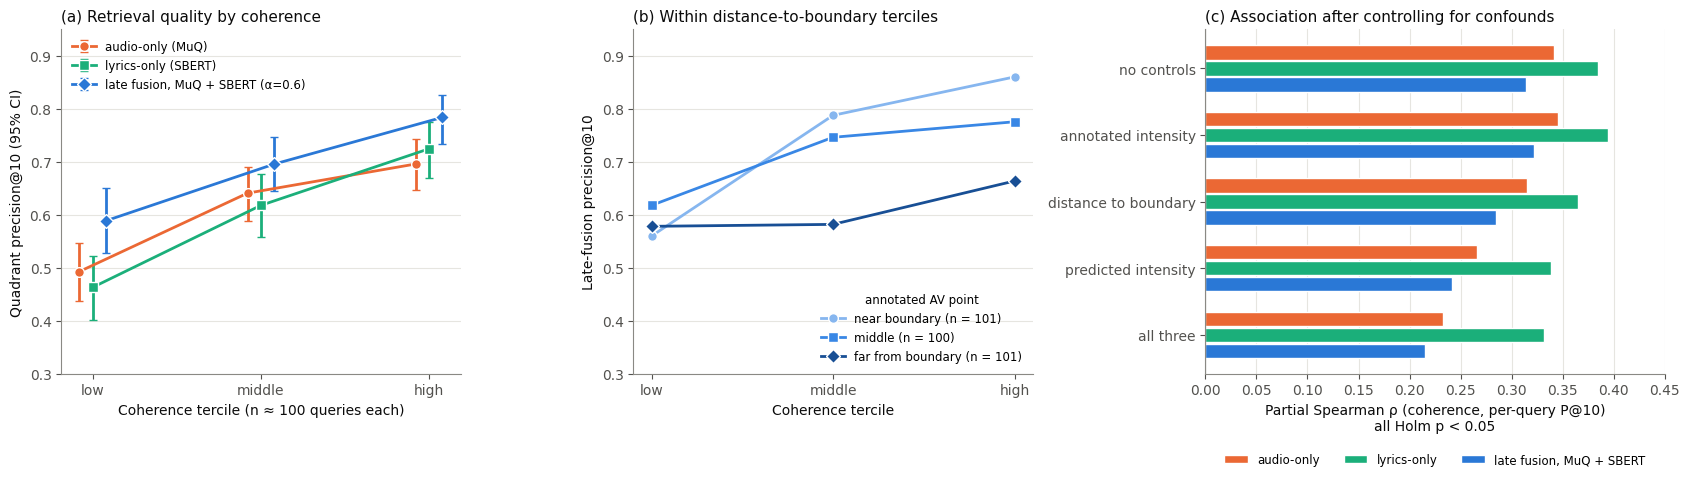

Saved: *_artist.csv and *_artist.png


In [12]:
coh = pd.read_parquet(os.path.join(OUT_DIR, 'coherence_muq.parquet')).set_index('song_id')
res = RES['70/15/15']; late = [k for k in res if k.startswith('late fusion (')][0]
qids = res['audio-only (MuQ)']['song_id']
cq = coh.loc[qids]
terc = pd.qcut(cq.coh_cos.values, 3, labels=['low', 'mid', 'high'])
bnd = np.minimum(np.abs(cq.arousal - 0.5), np.abs(cq.valence - 0.5)).values
bterc = pd.qcut(bnd, 3, labels=['near boundary', 'middle', 'far from boundary'])
conf = pd.read_csv(os.path.join(OUT_DIR, 'coherence_confound_check_muq_artist.csv'))

fig, axes = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={'width_ratios': [1, 1, 1.15]})
# (a) P@10 by coherence tercile for each strategy
ax = axes[0]; xs = np.arange(3)
for k, name in enumerate(['audio-only (MuQ)', 'lyrics-only (SBERT)', late]):
    st = style(name); v = res[name]['P@K'][:, 9]
    means, lo, hi = [], [], []
    for t_ in ['low', 'mid', 'high']:
        x = v[np.asarray(terc == t_)]; c = boot_ci(x, 2000); means.append(x.mean()); lo.append(x.mean() - c[0]); hi.append(c[1] - x.mean())
    off = (k - 1) * 0.08
    ax.errorbar(xs + off, means, yerr=[lo, hi], color=st['color'], marker=st['marker'], ms=7, mec='white', lw=2, capsize=3,
                label=st['label'])
ax.set_xticks(xs); ax.set_xticklabels(['low', 'middle', 'high']); ax.set_xlabel('Coherence tercile (n ≈ 100 queries each)')
ax.set_ylabel('Quadrant precision@10 (95% CI)'); ax.set_ylim(0.3, 0.95)
ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(a) Retrieval quality by coherence', loc='left')
ax.legend(fontsize=8.5, loc='upper left')
# (b) fused P@10 by coherence tercile within boundary-distance terciles (sequential blue: near → far)
ax = axes[1]; v = res[late]['P@K'][:, 9]
for b_, col, mk in zip(['near boundary', 'middle', 'far from boundary'], ['#86b6ef', '#3987e5', '#184f95'], ['o', 's', 'D']):
    sel = np.asarray(bterc == b_)
    means = [v[sel & np.asarray(terc == t_)].mean() for t_ in ['low', 'mid', 'high']]
    ns = [int((sel & np.asarray(terc == t_)).sum()) for t_ in ['low', 'mid', 'high']]
    ax.plot(xs, means, color=col, marker=mk, ms=7, mec='white', lw=2, label=f'{b_} (n = {sum(ns)})')
ax.set_xticks(xs); ax.set_xticklabels(['low', 'middle', 'high']); ax.set_xlabel('Coherence tercile')
ax.set_ylabel('Late-fusion precision@10'); ax.set_ylim(0.3, 0.95)
ax.grid(axis='y', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(b) Within distance-to-boundary terciles', loc='left')
ax.legend(fontsize=8.5, loc='lower right', title='annotated AV point', title_fontsize=8.5)
# (c) partial Spearman under each control set
ax = axes[2]
ctrl = ['none', 'label intensity', 'boundary distance', 'predicted intensity', 'all three']
outs = [('P10_audio_only', 'audio-only (MuQ)'), ('P10_lyrics_only', 'lyrics-only (SBERT)'), ('P10_late_0.6', late)]
y0 = np.arange(len(ctrl))[::-1]; h = 0.24
for k, (col, name) in enumerate(outs):
    st = style(name); g = conf[conf.outcome == col].set_index('controls').loc[ctrl]
    ax.barh(y0 + (1 - k) * h, g.partial_spearman, h * 0.9, color=st['color'], edgecolor='white', label=st['label'].split(' (')[0])
ax.axvline(0, color=INK2, lw=0.8)
ax.set_yticks(y0); ax.set_yticklabels(['no controls', 'annotated intensity', 'distance to boundary', 'predicted intensity', 'all three'])
ax.set_xlabel('Partial Spearman ρ (coherence, per-query P@10)\nall Holm p < 0.05'); ax.set_xlim(0, 0.45)
ax.grid(axis='x', color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title('(c) Association after controlling for confounds', loc='left')
ax.legend(fontsize=8.5, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'coherence_vs_retrieval_artist_cg.png'), dpi=200, bbox_inches='tight'); plt.show()
print('Saved: *_artist.csv and *_artist.png')